# 03 · Panel orientation from data

The CSV GTI uses the angles hard-coded in `openmeteo.py` (`tilt=40`, Open-Meteo `azimuth=40`, i.e. 40° west of south). Here GTI is rebuilt with pvlib from the satellite components (GHI, DNI, DHI) for a grid of tilt × azimuth, and each candidate is scored by its correlation with unconstrained PV power. Azimuth below uses the pvlib convention: 180 = south.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import load_joined, load_satellite, load_snapshots

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
STATE_COLORS = {
    "unconstrained": "tab:green",
    "curtailed": "tab:red",
    "unknown": "tab:orange",
    "dark": "lightgray",
}
import pvlib

In [2]:
LATITUDE, LONGITUDE = 50.387299, 30.385977

joined = load_joined()
data = joined[
    (joined["state"] == "unconstrained")
    & joined["shortwave_radiation"].notna()
]
# Satellite values average the 10 minutes before the label: take the sun
# position at the middle of that window.
times = data.index - pd.Timedelta(minutes=5)
sun = pvlib.location.Location(LATITUDE, LONGITUDE).get_solarposition(times)
pv = data["solar_power_w"].values


def poa(tilt, azimuth):
    poa_global = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        solar_zenith=sun["apparent_zenith"].values,
        solar_azimuth=sun["azimuth"].values,
        dni=data["direct_normal_irradiance"].values,
        ghi=data["shortwave_radiation"].values,
        dhi=data["diffuse_radiation"].values,
    )["poa_global"]
    return np.nan_to_num(poa_global)


tilts = np.arange(0, 91, 5)
azimuths = np.arange(90, 271, 10)
scores = pd.DataFrame(
    [[np.corrcoef(poa(t, a), pv)[0, 1] for a in azimuths] for t in tilts],
    index=tilts, columns=azimuths,
)
best_tilt, best_azimuth = scores.stack().idxmax()
print(f"best: tilt {best_tilt}°, azimuth {best_azimuth}° "
      f"(r = {scores.loc[best_tilt, best_azimuth]:.3f})")
print(f"CSV setting tilt 40°, azimuth 220°: r = {scores.loc[40, 220]:.3f}")

best: tilt 90°, azimuth 230° (r = 0.689)
CSV setting tilt 40°, azimuth 220°: r = 0.636


Text(0.5, 1.0, 'correlation of modelled POA with unconstrained PV')

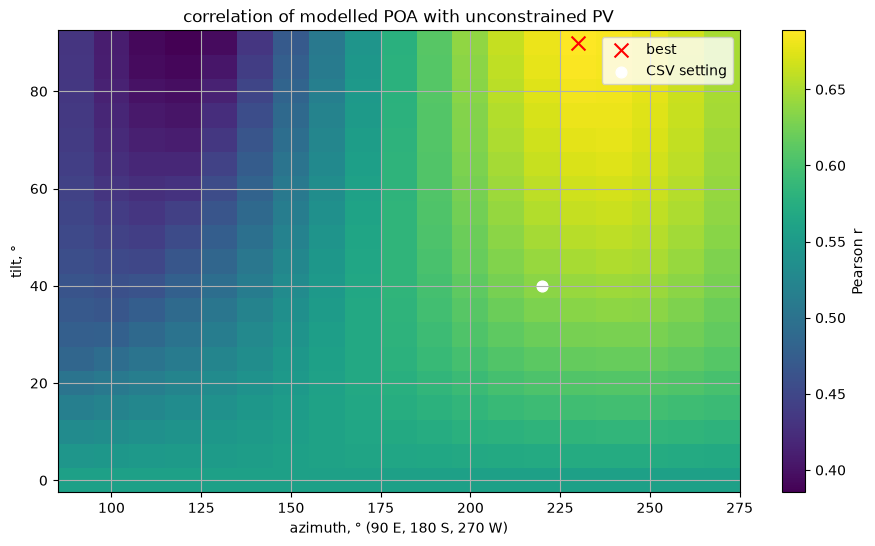

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(scores.values, origin="lower", aspect="auto", cmap="viridis",
               extent=[azimuths[0] - 5, azimuths[-1] + 5,
                       tilts[0] - 2.5, tilts[-1] + 2.5])
fig.colorbar(im, label="Pearson r")
ax.scatter([best_azimuth], [best_tilt], c="red", marker="x", s=100,
           label="best")
ax.scatter([220], [40], c="white", marker="o", s=60, label="CSV setting")
ax.set_xlabel("azimuth, ° (90 E, 180 S, 270 W)")
ax.set_ylabel("tilt, °")
ax.legend()
ax.set_title("correlation of modelled POA with unconstrained PV")

## Average daily profile

Mean PV power and modelled POA per 10-minute slot of the day, each normalised to its own peak. The shapes show when the array really peaks compared with each orientation.

Text(0, 0.5, 'normalised mean')

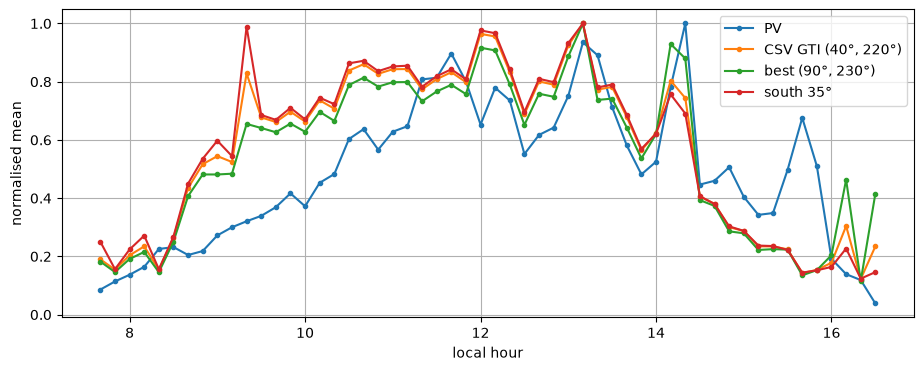

In [4]:
slot = data.index.tz_convert(TZ)
slot = slot.hour + slot.minute / 60
profiles = pd.DataFrame({
    "PV": pv,
    "CSV GTI (40°, 220°)": poa(40, 220),
    f"best ({best_tilt}°, {best_azimuth}°)": poa(best_tilt, best_azimuth),
    "south 35°": poa(35, 180),
}, index=slot).groupby(level=0).mean()
(profiles / profiles.max()).plot(figsize=(11, 4), marker=".")
plt.xlabel("local hour")
plt.ylabel("normalised mean")

> Only a few days of overlap, a single producing string (pv1) and possible shading mean this is a hint, not a measurement. If the best angles look plausible, confirm them against the real mounting before using them in `.env` (`PV_SITE_TILT_DEG`, `PV_SITE_AZIMUTH_DEG`).